In [24]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [25]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, r"c:\users\arthu\documents\swittz-epfl\phd\code\lib\site-packages")
sys.path.append('../')
from pygraphon.graphons import StepGraphon
from pygraphon.estimators import SmoothNetHist

from experiments.utils_generators import AssociativeFullyRandom
from pygraphon.norm import MseProbaEdge, MaeProbaEdge, AUCEdge, AUPRCEdge
from pygraphon.plots.plot_matrices import spy


In [26]:
from palettable.colorbrewer.sequential import YlOrRd_9
# To get the colors as a list of RGB tuples:
colors = YlOrRd_9.mpl_colors
hex_colors = YlOrRd_9.hex_colors
import matplotlib.cm as cm
import matplotlib.colors as colors
cmap = cm.get_cmap('YlOrRd')


# Common graphons

In [ ]:
from pygraphon.graphons import common_graphons
n = 40
estimators = {g: {"SSM": None, "Olhede": None} for _,g in enumerate(common_graphons.values())}
for j,g in enumerate(common_graphons.values()):
    adj_mat = g.draw(n=n, exchangeable=False)
    est = SmoothNetHist()
    est.fit(adj_mat)
    estimators[g]["SSM"] = est.graphon
    estimators[g]["Olhede"] = est._first_approximate_graphon_from_adjacency(adj_mat)


In [ ]:
from pygraphon.graphons import common_graphons
common_graphons

In [ ]:
#Plot each graphn and its estimate in subplots iteratively
fig, axes = plt.subplots(nrows=len(common_graphons.values()), ncols=3, figsize=(12, 20))
for j,g in enumerate(common_graphons.values()):
    axes[j,0].imshow(estimators[g]["SSM"].get_edge_probabilities(n,False,True)/estimators[g]["SSM"].initial_rho, cmap = cmap)
    axes[j,0].set_title("nLC = " + str(len(np.unique(estimators[g]["SSM"].graphon))))
    axes[j,1].imshow(estimators[g]["Olhede"][0].get_edge_probabilities(n,False,True)/estimators[g]["Olhede"][0].initial_rho, cmap = cmap)
    axes[j,1].set_title("nLC = " + str(len(np.unique(estimators[g]["Olhede"][0].graphon))))
    axes[j,2].imshow(g.get_edge_probabilities(n,False,True)/g.initial_rho, cmap = cmap, origin='lower')
    axes[j,2].set_title(str(g))
plt.tight_layout()
plt.show()

In [ ]:
#Plot each graphn and its estimate in subplots iteratively
fig, axes = plt.subplots(nrows=len(common_graphons.values()), ncols=3, figsize=(20, 20))
for j,g in enumerate(common_graphons.values()):
    axes[j,0].imshow(estimators[g]["SSM"].get_edge_probabilities(n,False,True)**0.25, cmap = cmap)
    axes[j,0].set_title("nLC = " + str(len(np.unique(estimators[g]["SSM"].graphon))))
    axes[j,1].imshow(estimators[g]["Olhede"][0].get_edge_probabilities(n,False,True)**0.25, cmap = cmap)
    axes[j,1].set_title("nLC = " + str(len(np.unique(estimators[g]["Olhede"][0].graphon))))
    axes[j,2].imshow(g.get_edge_probabilities(n,False,True)**0.25, cmap = cmap)
    axes[j,2].set_title(str(g))
plt.tight_layout()
plt.show()

# HSBM, overlap, and partition model

## HSBM and partition

In [27]:
import numpy as np

def generate_hierarchical_theta(k, m, theta_min_intra, theta_max_intra, theta_min_meta_intra, theta_max_meta_intra, theta_min_inter, theta_max_inter):
    """
    Generate a symmetric hierarchical connectivity matrix θ for an HSBM.

    Parameters:
    - k: total number of blocks
    - m: number of meta-blocks
    - theta_min_intra, theta_max_intra: intra-connectivity range within a block
    - theta_min_meta_intra, theta_max_meta_intra: intra-connectivity range within a meta-block but across blocks
    - theta_min_inter, theta_max_inter: inter-connectivity range between meta-blocks

    Returns:
    - θ: k x k symmetric hierarchical connectivity matrix
    """

    # Check if k is divisible by m
    if k % m != 0:
        raise ValueError("k should be divisible by m for a uniform hierarchical structure.")

    n = k // m  # Number of blocks within each meta-block

    theta = np.zeros((k, k))

    for i in range(k):
        for j in range(i, k):  # Only loop over the upper triangle including the diagonal
            # Determine meta-blocks for i and j
            meta_block_i = i // n
            meta_block_j = j // n

            if meta_block_i == meta_block_j:
                # Within the same meta-block
                if i == j:
                    # Same block: intra-connectivity
                    theta[i, j] = np.random.uniform(theta_min_intra, theta_max_intra)
                else:
                    # Different block but same meta-block: meta-intra-connectivity
                    theta[i, j] = np.random.uniform(theta_min_meta_intra, theta_max_meta_intra)
            else:
                # Different meta-blocks: inter-connectivity
                theta[i, j] = np.random.uniform(theta_min_inter, theta_max_inter)
            
            # Make the matrix symmetric
            theta[j, i] = theta[i, j]

    return theta

# Example usage:
k = 9
m = 3
theta_min_intra = 0.7
theta_max_intra = 0.9
theta_min_meta_intra = 0.4
theta_max_meta_intra = 0.4
theta_min_inter = 0.2
theta_max_inter = 0.2

# put theta_inter's and theta_meta_intra's to equality to get partition model

theta = generate_hierarchical_theta(k, m, theta_min_intra, theta_max_intra, theta_min_meta_intra, theta_max_meta_intra, theta_min_inter, theta_max_inter)
print(theta)


[[0.81109937 0.4        0.4        0.2        0.2        0.2
  0.2        0.2        0.2       ]
 [0.4        0.81417793 0.4        0.2        0.2        0.2
  0.2        0.2        0.2       ]
 [0.4        0.4        0.74856815 0.2        0.2        0.2
  0.2        0.2        0.2       ]
 [0.2        0.2        0.2        0.87791951 0.4        0.4
  0.2        0.2        0.2       ]
 [0.2        0.2        0.2        0.4        0.75795629 0.4
  0.2        0.2        0.2       ]
 [0.2        0.2        0.2        0.4        0.4        0.75829889
  0.2        0.2        0.2       ]
 [0.2        0.2        0.2        0.2        0.2        0.2
  0.79337577 0.4        0.4       ]
 [0.2        0.2        0.2        0.2        0.2        0.2
  0.4        0.77633032 0.4       ]
 [0.2        0.2        0.2        0.2        0.2        0.2
  0.4        0.4        0.81197371]]


In [28]:
graphon = StepGraphon(theta, bandwidthHist=1 / k)
print(graphon)

StepGraphon 
[[0.811 0.400 0.400 0.200 0.200 0.200 0.200 0.200 0.200]
 [0.400 0.814 0.400 0.200 0.200 0.200 0.200 0.200 0.200]
 [0.400 0.400 0.749 0.200 0.200 0.200 0.200 0.200 0.200]
 [0.200 0.200 0.200 0.878 0.400 0.400 0.200 0.200 0.200]
 [0.200 0.200 0.200 0.400 0.758 0.400 0.200 0.200 0.200]
 [0.200 0.200 0.200 0.400 0.400 0.758 0.200 0.200 0.200]
 [0.200 0.200 0.200 0.200 0.200 0.200 0.793 0.400 0.400]
 [0.200 0.200 0.200 0.200 0.200 0.200 0.400 0.776 0.400]
 [0.200 0.200 0.200 0.200 0.200 0.200 0.400 0.400 0.812]]

 [0.012 0.012 0.012 0.012 0.012 0.012 0.012 0.012 0.012] (size of the blocks)


In [35]:
n=400
adj_mat = graphon.draw(n=n, exchangeable=False)
est = SmoothNetHist(restriction=False)
est.fit(adj_mat)
estimators_SSM = est.graphon
estimators_Olhede = est._first_approximate_graphon_from_adjacency(adj_mat)

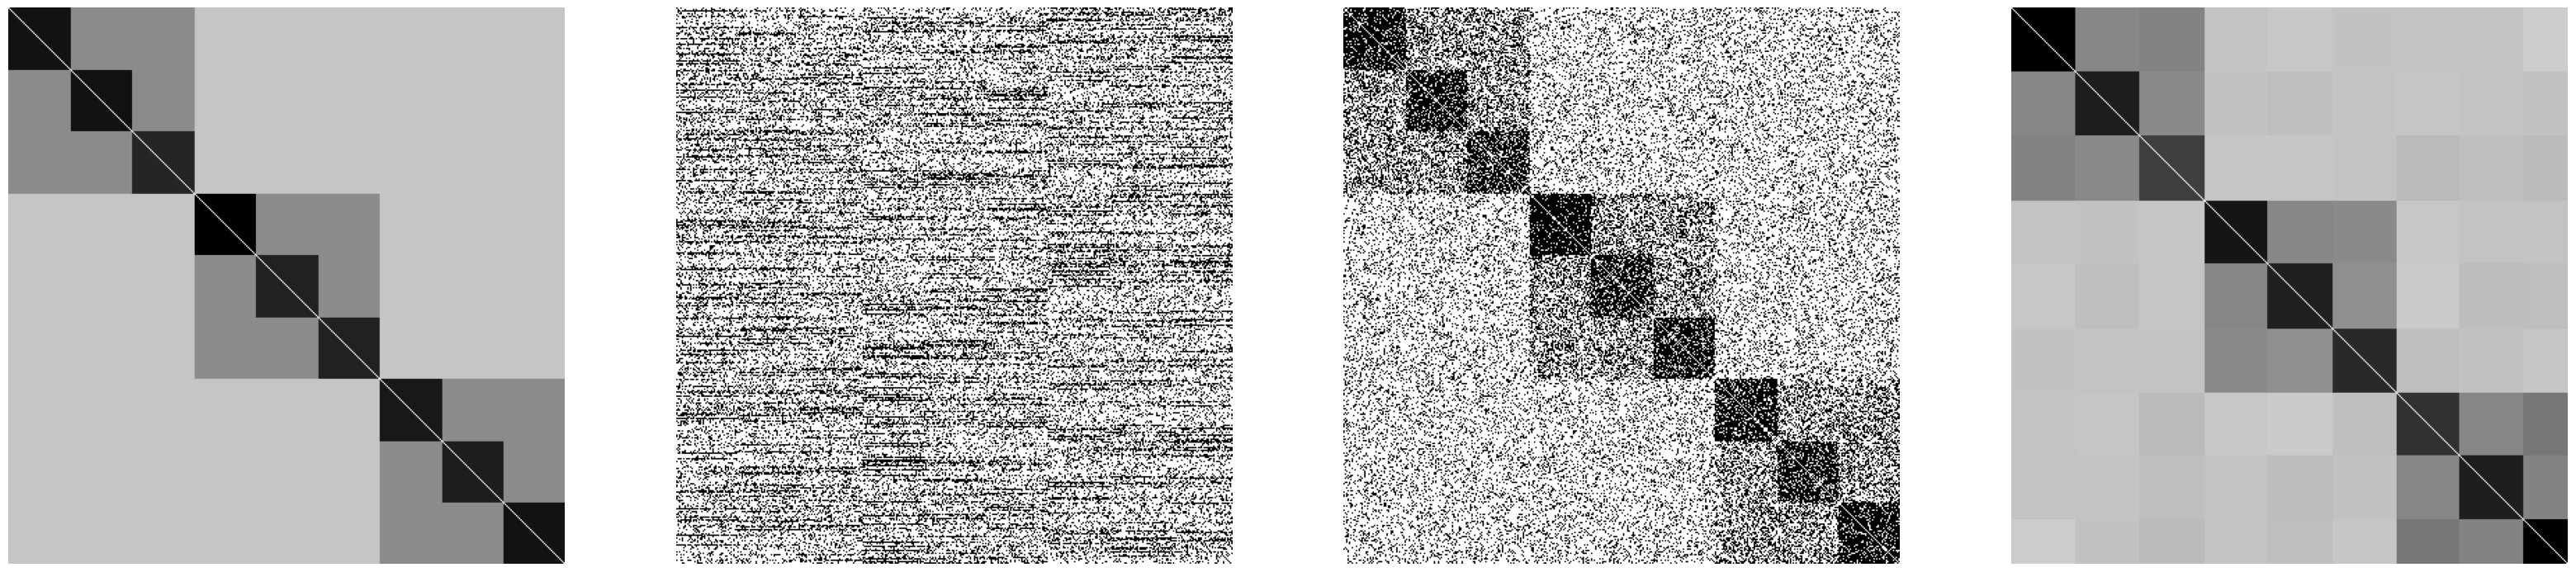

In [78]:
from pygraphon.plots.utils import make_pretty
# Plot Olhede's estimate along with adjacency matrix and randomly permuted adjacency matrix
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(40, 10))

#Give black and white cmap
cmap = plt.cm.binary
axes[0].imshow(graphon.get_edge_probabilities(n,False,True)/graphon.initial_rho, cmap = cmap)
make_pretty(ax=axes[0])
axes[1].imshow(np.random.permutation(adj_mat), cmap = cmap)
make_pretty(ax=axes[1])
axes[2].imshow(adj_mat, cmap = cmap)
make_pretty(ax=axes[2])
axes[3].imshow(estimators_Olhede[0].get_edge_probabilities(n,False,True), cmap = cmap)
make_pretty(ax=axes[3])

plt.show()

In [44]:
# testing colorbrewer colours
from palettable.colorbrewer.sequential import YlOrRd_9
# To get the colors as a list of RGB tuples:
colors = YlOrRd_9.mpl_colors

# To get the colors as a list of hex strings:
hex_colors = YlOrRd_9.hex_colors

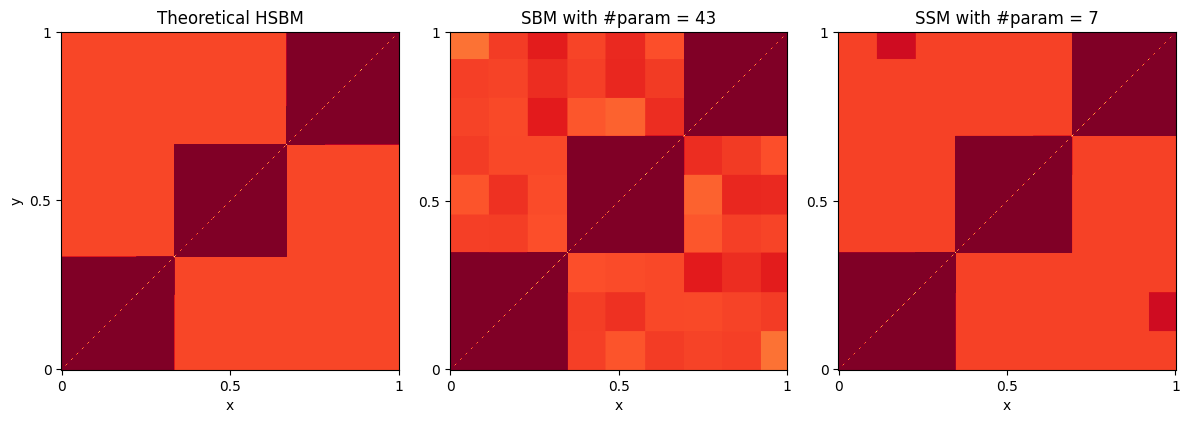

In [45]:
xticks = [0, n/ 2, n - 1]
yticks = [0, n/ 2, n - 1]

fig, axes = plt.subplots(ncols=3, figsize=(12, 20))

axes[0].imshow((graphon.get_edge_probabilities(n,False,True)/graphon.initial_rho)**1.0, cmap=YlOrRd_9.mpl_colormap, vmin=0, vmax=1, origin='lower')
axes[0].set_title("Theoretical SBM")

axes[1].imshow(np.rot90(estimators_Olhede[0].get_edge_probabilities(n,False,True)/estimators_Olhede[0].initial_rho)**1.0, cmap=YlOrRd_9.mpl_colormap, vmin=0, vmax=1)
axes[1].set_title("SBM with #param = " + str(len(np.unique(estimators_Olhede[0].graphon))))

axes[2].imshow(np.rot90(estimators_SSM.get_edge_probabilities(n,False,True)/estimators_SSM.initial_rho)**1.0, cmap=YlOrRd_9.mpl_colormap, vmin=0, vmax=1)
axes[2].set_title("SSM with #param = " + str(len(np.unique(estimators_SSM.graphon))))

permutation_label_str = [None, "SSM", "SBM"]
for i, perm in enumerate(permutation_label_str):
    if perm == None:
        pparam = dict(xlabel=f'x', ylabel=f'y')

        axes[i].set_xticks(xticks)
        axes[i].set_yticks(yticks)
        axes[i].set_xticklabels(['0', '0.5', '1'])
        axes[i].set_yticklabels(['0', '0.5', '1'])
        axes[i].set(**pparam)
    else:
        pparam = dict(xlabel=f'x')
        axes[i].set_xticks(xticks)
        axes[i].set_yticks(yticks)
        axes[i].set_xticklabels(['0', '0.5', '1'])
        axes[i].set_yticklabels(['1', '0.5', '0'])
        axes[i].set(**pparam)

plt.tight_layout()
plt.show()

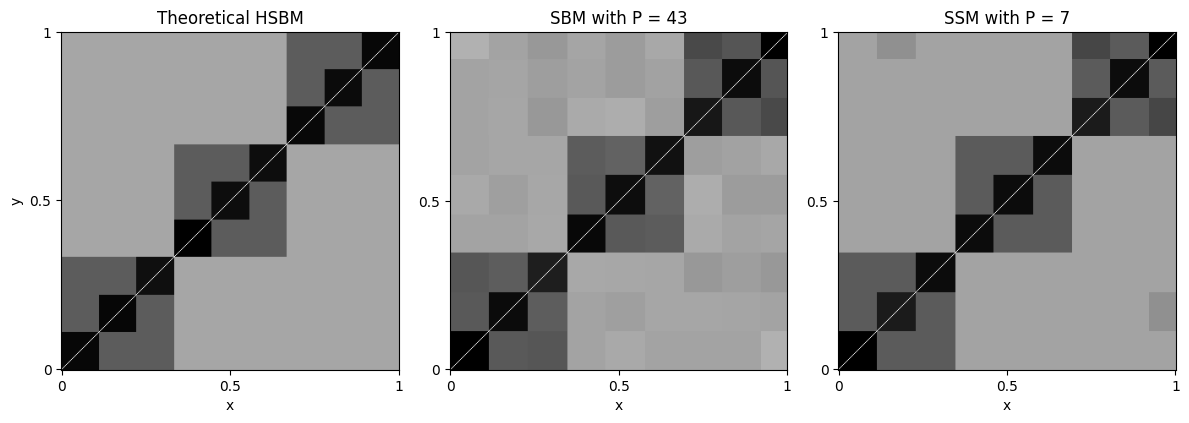

In [80]:
import numpy as np
from pygraphon.plots.plots_graphon import _add_colorbar

def sigmoid_2d(array):
    return 1 / (1 + np.exp(-array))

xticks = [0, n/ 2, n - 1]
yticks = [0, n/ 2, n - 1]

fig, axes = plt.subplots(ncols=3, figsize=(12, 20))

axes[0].imshow(sigmoid_2d(graphon.get_edge_probabilities(n,False,True)/graphon.initial_rho),cmap=cmap, origin='lower')
axes[0].set_title("Theoretical SBM")

axes[1].imshow(np.rot90(sigmoid_2d(estimators_Olhede[0].get_edge_probabilities(n,False,True)/estimators_Olhede[0].initial_rho)), cmap=cmap)
axes[1].set_title("SBM with P = " + str(len(np.unique(estimators_Olhede[0].graphon))))

axes[2].imshow(np.rot90(sigmoid_2d(estimators_SSM.get_edge_probabilities(n,False,True)/estimators_SSM.initial_rho)), cmap=cmap)
axes[2].set_title("SSM with P = " + str(len(np.unique(estimators_SSM.graphon))))

permutation_label_str = [None, "SSM", "SBM"]
for i, perm in enumerate(permutation_label_str):
    if perm == None:
        pparam = dict(xlabel=f'x', ylabel=f'y')

        axes[i].set_xticks(xticks)
        axes[i].set_yticks(yticks)
        axes[i].set_xticklabels(['0', '0.5', '1'])
        axes[i].set_yticklabels(['0', '0.5', '1'])
        axes[i].set(**pparam)
    else:
        pparam = dict(xlabel=f'x')
        axes[i].set_xticks(xticks)
        axes[i].set_yticks(yticks)
        axes[i].set_xticklabels(['0', '0.5', '1'])
        axes[i].set_yticklabels(['1', '0.5', '0'])
        axes[i].set(**pparam)
plt.tight_layout()
plt.show()

## OSBM

In [ ]:
import numpy as np

def generate_osbm_theta(k, shared_inter_sets, theta_min_intra, theta_max_intra, theta_min_inter, theta_max_inter):
    """
    Generate a symmetric connectivity matrix θ for an OSBM with specific inter-connectivity behavior.

    Parameters:
    - k: total number of blocks (should be at least 3)
    - shared_inter_sets: number of sets of blocks with shared inter-connectivity values
    - theta_min_intra, theta_max_intra: intra-connectivity range within a block
    - theta_min_inter, theta_max_inter: inter-connectivity range between blocks

    Returns:
    - θ: k x k symmetric connectivity matrix for OSBM
    """
    
    if k < 3:
        raise ValueError("The number of blocks k should be at least 3.")

    theta = np.zeros((k, k))
    shared_sets = [np.random.choice(k, 3, replace=False) for _ in range(shared_inter_sets)]

    for i in range(k):
        for j in range(i, k):  # Only loop over the upper triangle including the diagonal
            
            shared_value = None
            for shared_set in shared_sets:
                if i in shared_set and j in shared_set and i != j:
                    if shared_value is None:
                        shared_value = np.random.uniform(theta_min_inter, theta_max_inter)
                    theta[i, j] = shared_value
                    break

            if i == j:
                theta[i, j] = np.random.uniform(theta_min_intra, theta_max_intra)
            elif theta[i, j] == 0:
                theta[i, j] = np.random.uniform(theta_min_inter, theta_max_inter)
            
            # Make the matrix symmetric
            theta[j, i] = theta[i, j]

    return theta

# Example usage:
k = 5
shared_inter_sets = 2
theta_min_intra = 0.7
theta_max_intra = 1.0
theta_min_inter = 0.1
theta_max_inter = 0.3

theta = generate_osbm_theta(k, shared_inter_sets, theta_min_intra, theta_max_intra, theta_min_inter, theta_max_inter)
print(theta)


# SSM